# Model Training, Deployment & Monitoring

**Author: Manideep.**

This notebook covers the Week 4 and Week 5 project steps: a simple benchmark, a trained model
evaluated against that benchmark, deployment to a live SageMaker endpoint, and model/data/
infrastructure monitoring on that endpoint. It reads the feature tables written by
`A_data_feature_engineering.ipynb`, so run that notebook first.

**Models covered:**
1. A **heuristic benchmark** — fixed threshold rules on two features, no training involved. This
   is the minimum-viable baseline everything else has to beat.
2. A **Random Forest**, evaluated two ways:
   - An ordinary holdout (train on the training subjects, score on the held-out test subject).
   - **Leave-One-Subject-Out (LOSO) cross-validation**: train 9 times, each time holding out one
     subject entirely, then averaging the score across all 9 held-out subjects. This answers
     "how well does this generalize to a person the model has never seen", which a single
     holdout subject cannot answer on its own (one held-out person is one data point).
3. The final Random Forest (trained on every subject) deployed to a real-time SageMaker
   **endpoint**, with data capture, model/data monitors, CloudWatch alarms, and a dashboard.

## 1. Bootstrap

In [1]:
import sys, pathlib
PROJECT_ROOT = pathlib.Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import io, json, time
import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sagemaker
from sagemaker.sklearn.estimator import SKLearn
from sagemaker.model_monitor import DataCaptureConfig

from src.pamap2.config import load_config, s3_uri
from src.pamap2.evaluation import classification_metrics, compare

cfg = load_config()
BUCKET = cfg["bucket"]
ROLE = cfg["role_arn"]

boto_session = boto3.Session(region_name=cfg["region"])
sm_session = sagemaker.Session(boto_session=boto_session, default_bucket=BUCKET)
print("Caller:", boto_session.client("sts").get_caller_identity()["Arn"])

s3 = boto_session.client("s3")
cw = boto_session.client("cloudwatch")

FEATURES_PREFIX = cfg["s3_prefixes"]["features"] + "v2/"
ENDPOINT_NAME = "pamap2-har-rf-endpoint"
MODEL_PACKAGE_GROUP = "pamap2-har-rf"
DASHBOARD_NAME = "pamap2-har-rf-ml"
ALARM_PREFIX = "pamap2-har-rf"
pathlib.Path("scripts").mkdir(exist_ok=True)


sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml


/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


Caller: arn:aws:sts::836620944282:assumed-role/AmazonSageMaker-ExecutionRole-20261015T160795/SageMaker


## 2. Load the feature tables written by the data-engineering notebook

In [2]:
def read_s3_csv(key, header=None):
    return pd.read_csv(io.BytesIO(s3.get_object(Bucket=BUCKET, Key=key)["Body"].read()), header=header)

def read_s3_json(key):
    return json.loads(s3.get_object(Bucket=BUCKET, Key=key)["Body"].read())

FEATURE_COLUMNS = read_s3_json(FEATURES_PREFIX + "feature_columns.json")
LABEL_MAP = {r["label"]: r["activity_id"] for r in read_s3_json(FEATURES_PREFIX + "label_map.json")}
CLASSES = sorted(LABEL_MAP.keys())

col_names = ["label", *FEATURE_COLUMNS]
train_df = read_s3_csv(FEATURES_PREFIX + "train.csv"); train_df.columns = col_names
validation_df = read_s3_csv(FEATURES_PREFIX + "validation.csv"); validation_df.columns = col_names
test_df = read_s3_csv(FEATURES_PREFIX + "test.csv"); test_df.columns = col_names

print("train:", train_df.shape, "| validation:", validation_df.shape, "| test:", test_df.shape)
print(len(CLASSES), "classes")


train: (7470, 183) | validation: (909, 183) | test: (1545, 183)
17 classes


## 3. Benchmark: a fixed-threshold heuristic (no training)

Buckets each window by acceleration-magnitude variability and heart rate into a small number of
activity guesses. It is deliberately simple — three hand-picked thresholds, not a fitted model —
to serve as the minimum-viable baseline: if the trained model can't beat a handful of if/else
rules, it isn't earning its complexity.

In [3]:
ACC_STD_COL = "chest_acc16_x_std"   # how much the chest accelerometer's x-axis varies in the window
HR_COL = "hr_mean"

def heuristic_benchmark(df):
    acc_std = df[ACC_STD_COL].fillna(df[ACC_STD_COL].median())
    hr = df[HR_COL].fillna(df[HR_COL].median())
    # Low movement + low heart rate -> most common sedentary class; low movement + high heart
    # rate -> most common seated-but-active class; everything else -> most common moving class.
    sedentary, seated_active, moving = (train_df["label"].value_counts().index[:3].tolist() + [CLASSES[0]] * 3)[:3]
    predictions = np.where(acc_std < acc_std.median(),
                            np.where(hr < hr.median(), sedentary, seated_active),
                            moving)
    return predictions.astype(int)

benchmark_val_pred = heuristic_benchmark(validation_df)
benchmark_test_pred = heuristic_benchmark(test_df)
benchmark_test_metrics = classification_metrics(test_df["label"], benchmark_test_pred, CLASSES)
print(f"Benchmark macro-F1 (test subject): {benchmark_test_metrics['macro_f1']:.3f} | "
      f"accuracy: {benchmark_test_metrics['accuracy']:.3f}")


Benchmark macro-F1 (test subject): 0.007 | accuracy: 0.025


## 4. Leave-One-Subject-Out cross-validation, as a SageMaker Processing Job

Nine folds, one whole subject held out per fold, a Random Forest trained on the other eight each
time. The folds run inside a managed SageMaker job, so this notebook's own instance only has to
read the results. `LOSO_INSTANCE` controls the job's machine: larger instances have more cores and
finish faster (the Random Forest uses every core), at a higher hourly price for a job that lasts
minutes.

Each fold scores only on activities the other eight subjects also performed (a held-out subject
cannot be evaluated on an activity nothing in training ever demonstrated). The job reuses
`pamap2.evaluation.classification_metrics`, shipped into the container as a dependency.

In [4]:
%%writefile scripts/loso_job.py
"""Leave-One-Subject-Out evaluation of a Random Forest, run inside a SageMaker Processing container.

Reads loso_source.parquet and feature_columns.json from /opt/ml/processing/input, writes one row
per held-out subject to /opt/ml/processing/output/loso_results.csv. pamap2.evaluation is available
because the launching notebook ships src/pamap2 as a processor dependency.
"""
import json
import os

import pandas as pd
from sklearn.ensemble import RandomForestClassifier

from pamap2.evaluation import classification_metrics

INPUT_DIR = "/opt/ml/processing/input"
OUTPUT_DIR = "/opt/ml/processing/output"


def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    data = pd.read_parquet(os.path.join(INPUT_DIR, "loso_source.parquet"))
    with open(os.path.join(INPUT_DIR, "feature_columns.json")) as f:
        feature_columns = json.load(f)
    data = data.dropna(subset=feature_columns)

    rows = []
    for subject in sorted(data["subject_id"].unique().tolist()):
        train_fold = data[data["subject_id"] != subject]
        test_fold = data[data["subject_id"] == subject]
        fold_classes = sorted(train_fold["activity_id"].unique().tolist())
        test_fold = test_fold[test_fold["activity_id"].isin(fold_classes)]

        model = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=0)
        model.fit(train_fold[feature_columns].to_numpy(float), train_fold["activity_id"].to_numpy(int))

        if len(test_fold):
            predictions = model.predict(test_fold[feature_columns].to_numpy(float))
            metrics = classification_metrics(test_fold["activity_id"], predictions, fold_classes)
            macro_f1, accuracy = metrics["macro_f1"], metrics["accuracy"]
        else:
            macro_f1 = accuracy = float("nan")

        rows.append({"subject": int(subject), "n_train": len(train_fold), "n_test": len(test_fold),
                     "macro_f1": macro_f1, "accuracy": accuracy})
        print(f"subject {subject}: train={len(train_fold)} test={len(test_fold)} macro_f1={macro_f1:.3f}", flush=True)

    pd.DataFrame(rows).to_csv(os.path.join(OUTPUT_DIR, "loso_results.csv"), index=False)


if __name__ == "__main__":
    main()

Overwriting scripts/loso_job.py


In [5]:
from sagemaker.processing import FrameworkProcessor, ProcessingInput, ProcessingOutput

LOSO_INSTANCE = "ml.m5.xlarge"      # change to e.g. "ml.m5.4xlarge" for more cores and a faster run
LOSO_OUTPUT = s3_uri(cfg, "features", "v2/loso-results/")

loso_processor = FrameworkProcessor(
    estimator_cls=SKLearn, framework_version="1.2-1", role=ROLE,
    instance_type=LOSO_INSTANCE, instance_count=1, volume_size_in_gb=30,
    sagemaker_session=sm_session, base_job_name="pamap2-har-loso")

loso_processor.run(
    code="loso_job.py", source_dir="scripts", dependencies=[str(PROJECT_ROOT / "src" / "pamap2")],
    inputs=[ProcessingInput(source=s3_uri(cfg, "features", "v2/"), destination="/opt/ml/processing/input")],
    outputs=[ProcessingOutput(source="/opt/ml/processing/output", destination=LOSO_OUTPUT)],
)

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/processing.py:138: SageMakerV2DeprecationWarning: FrameworkProcessor is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `DataProcessor` (`from sagemaker.mlops.processing import DataProcessor`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
FrameworkProcessor is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `DataProcessor` (`from sagemaker.mlops.processing import DataProcessor`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/estimator.py:588: SageMakerV2DeprecationWarning: SKLearn is part of the SageMaker Python SDK v2, whic

..............subject 101: train=8623 test=1294 macro_f1=0.620
subject 102: train=9429 test=1028 macro_f1=0.917
subject 103: train=9774 test=683 macro_f1=0.935
subject 104: train=9553 test=904 macro_f1=0.936
subject 105: train=8849 test=1608 macro_f1=0.823
subject 106: train=9044 test=1413 macro_f1=0.803
subject 107: train=9548 test=909 macro_f1=0.937
subject 108: train=8912 test=1545 macro_f1=0.708
subject 109: train=9924 test=533 macro_f1=0.604



In [6]:
loso_results = read_s3_csv(cfg["s3_prefixes"]["features"] + "v2/loso-results/loso_results.csv", header=0)
loso_mean, loso_std = loso_results["macro_f1"].mean(), loso_results["macro_f1"].std()
print(f"LOSO macro-F1: {loso_mean:.3f} +/- {loso_std:.3f} across {len(loso_results)} subjects")
display(loso_results)

LOSO macro-F1: 0.809 +/- 0.136 across 9 subjects


,subject,n_train,n_test,macro_f1,accuracy
0,101,8623,1294,0.619736,0.604328
1,102,9429,1028,0.916823,0.884241
2,103,9774,683,0.934912,0.926794
3,104,9553,904,0.936476,0.926991
4,105,8849,1608,0.823140,0.747512
5,106,9044,1413,0.802532,0.827318
6,107,9548,909,0.937012,0.931793
7,108,8912,1545,0.707663,0.642071
8,109,9924,533,0.604150,0.540338


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


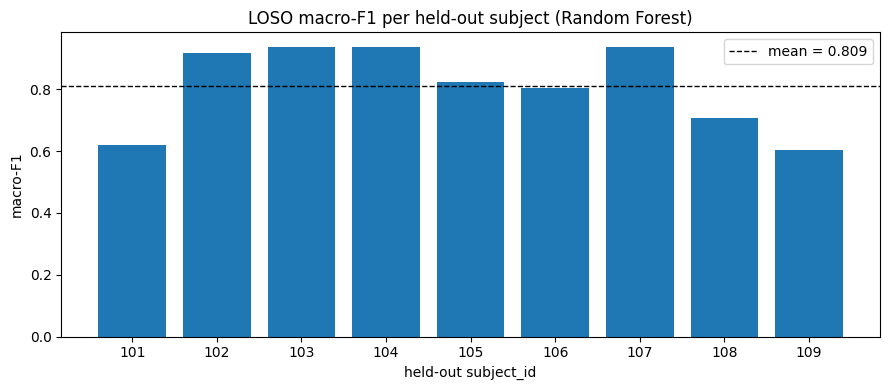

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(loso_results["subject"].astype(str), loso_results["macro_f1"])
ax.axhline(loso_mean, color="black", linestyle="--", linewidth=1, label=f"mean = {loso_mean:.3f}")
ax.set_xlabel("held-out subject_id"); ax.set_ylabel("macro-F1")
ax.set_title("LOSO macro-F1 per held-out subject (Random Forest)")
ax.legend()
plt.tight_layout(); plt.show()


## 5. Train the deployed Random Forest as a real SageMaker Training Job

Trains on the ordinary train/validation split from the data-engineering notebook. `src/pamap2` is
shipped into the training container as a `dependencies=[...]` entry (see the `SKLearn` estimator
below), so the script reuses `pamap2.evaluation.classification_metrics` for the validation score
instead of re-implementing macro-F1. It also includes the `model_fn` / `input_fn` / `predict_fn` /
`output_fn` functions the SageMaker SKLearn inference container needs to serve this model behind
a real-time endpoint.

In [8]:
%%writefile scripts/train.py
"""Trains a Random Forest activity classifier and serves it behind a SageMaker endpoint.

Training entry point: reads SM_CHANNEL_TRAIN/SM_CHANNEL_VALIDATION CSVs (label in column 0),
fits a RandomForestClassifier, saves it with joblib, and prints validation accuracy/macro-F1 (via
the existing pamap2.evaluation.classification_metrics) so they show up in the training job's
CloudWatch logs.

Inference entry points (model_fn/input_fn/predict_fn/output_fn): loaded by the SageMaker SKLearn
inference container to serve predictions over HTTP once this model is deployed to an endpoint.

pamap2.evaluation is available here because the SKLearn Estimator that launches this job passes
dependencies=[".../src/pamap2"], which uploads that folder alongside this script.
"""
import argparse
import json
import os

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

from pamap2.evaluation import classification_metrics


def _read_csv(path):
    files = [os.path.join(path, f) for f in os.listdir(path) if f.endswith(".csv")]
    frame = pd.concat((pd.read_csv(f, header=None) for f in files), ignore_index=True)
    return frame.iloc[:, 0].to_numpy(int), frame.iloc[:, 1:].to_numpy(float)


def train():
    parser = argparse.ArgumentParser()
    parser.add_argument("--n-estimators", type=int, default=300)
    parser.add_argument("--min-samples-leaf", type=int, default=2)
    parser.add_argument("--max-depth", type=int, default=0)  # 0 -> sklearn's "unlimited" (None)
    parser.add_argument("--train", type=str, default=os.environ["SM_CHANNEL_TRAIN"])
    parser.add_argument("--validation", type=str, default=os.environ["SM_CHANNEL_VALIDATION"])
    parser.add_argument("--model-dir", type=str, default=os.environ["SM_MODEL_DIR"])
    args = parser.parse_args()

    y_train, x_train = _read_csv(args.train)
    y_val, x_val = _read_csv(args.validation)

    model = RandomForestClassifier(n_estimators=args.n_estimators,
                                    min_samples_leaf=args.min_samples_leaf,
                                    max_depth=args.max_depth or None,  # 0 -> sklearn's "unlimited"
                                    n_jobs=-1, random_state=0)
    model.fit(x_train, y_train)

    val_pred = model.predict(x_val)
    val_classes = sorted(set(y_train.tolist()) | set(y_val.tolist()))
    val_metrics = classification_metrics(y_val, val_pred, val_classes)
    accuracy, macro_f1 = val_metrics["accuracy"], val_metrics["macro_f1"]
    print(f"validation_accuracy={accuracy:.4f}")
    print(f"validation_macro_f1={macro_f1:.4f}")

    joblib.dump(model, os.path.join(args.model_dir, "model.joblib"))
    with open(os.path.join(args.model_dir, "metrics.json"), "w") as f:
        json.dump({"validation_accuracy": accuracy, "validation_macro_f1": macro_f1}, f)


def model_fn(model_dir):
    """Load the trained model when the endpoint container starts."""
    return joblib.load(os.path.join(model_dir, "model.joblib"))


def input_fn(request_body, content_type):
    """Parse an incoming inference request: a JSON list of feature rows."""
    if content_type == "application/json":
        payload = json.loads(request_body)
        return np.array(payload["instances"], dtype=float)
    raise ValueError(f"Unsupported content type: {content_type}")


def predict_fn(input_data, model):
    """Run the model and return predicted class indices."""
    return model.predict(input_data)


def output_fn(prediction, accept):
    """Serialize predictions back to JSON."""
    if accept == "application/json":
        return json.dumps({"predictions": prediction.tolist()}), accept
    raise ValueError(f"Unsupported accept type: {accept}")


if __name__ == "__main__":
    train()


Overwriting scripts/train.py


### 5a. Hyperparameter tuning

Rather than guessing `n-estimators` / `min-samples-leaf` / `max-depth` by hand, a small SageMaker
**Hyperparameter Tuning job** launches a handful of training jobs across a search space and picks
the one that maximizes `validation:macro_f1` -- the exact number `train.py` already prints to its
logs (`validation_macro_f1=...`), picked up here via `metric_definitions`'s regex. The search
space is narrow and `max_jobs` is small (4 jobs, 2 at a time) -- the point is to demonstrate the
HPO workflow, not to run an exhaustive search.

In [9]:
from sagemaker.tuner import HyperparameterTuner, IntegerParameter

estimator = SKLearn(
    entry_point="train.py", source_dir="scripts", dependencies=[str(PROJECT_ROOT / "src" / "pamap2")],
    role=ROLE, instance_type="ml.m5.large",
    instance_count=1, framework_version="1.2-1", py_version="py3", sagemaker_session=sm_session,
    base_job_name="pamap2-har-rf-train",
)

tuner = HyperparameterTuner(
    estimator=estimator,
    objective_metric_name="validation:macro_f1",
    objective_type="Maximize",
    metric_definitions=[{"Name": "validation:macro_f1", "Regex": r"validation_macro_f1=([0-9.]+)"}],
    hyperparameter_ranges={
        "n-estimators": IntegerParameter(150, 350),
        "min-samples-leaf": IntegerParameter(1, 4),
        "max-depth": IntegerParameter(8, 20),
    },
    strategy="Bayesian",
    max_jobs=4, max_parallel_jobs=2,
    base_tuning_job_name="pamap2-har-rf-hpo",
)

tuner.fit({
    "train": s3_uri(cfg, "features", "v2/train.csv"),
    "validation": s3_uri(cfg, "features", "v2/validation.csv"),
})


/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/tuner.py:689: SageMakerV2DeprecationWarning: HyperparameterTuner is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use the hyperparameter tuning classes under sagemaker.core.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
INFO:sagemaker:Creating hyperparameter tuning job with name: pamap2-har-rf-hpo-261016-0548


.............................................................!


In [10]:
tuning_results = tuner.analytics().dataframe().sort_values("FinalObjectiveValue", ascending=False)
display(tuning_results[["TrainingJobName", "n-estimators", "min-samples-leaf", "max-depth",
                        "FinalObjectiveValue"]])

best_estimator = tuner.best_estimator()
print("Best training job:", tuner.best_training_job())
print("Best hyperparameters:", best_estimator.hyperparameters())


,TrainingJobName,n-estimators,min-samples-leaf,max-depth,FinalObjectiveValue
0,pamap2-har-rf-hpo-261016-0548-004-6571a1bb,278.0,4.0,15.0,0.9452
3,pamap2-har-rf-hpo-261016-0548-001-54845c9e,328.0,2.0,13.0,0.9442
2,pamap2-har-rf-hpo-261016-0548-002-f3966994,348.0,4.0,20.0,0.9421
1,pamap2-har-rf-hpo-261016-0548-003-53a7e5be,266.0,1.0,10.0,0.9356



2026-10-16 05:53:38 Starting - Found matching resource for reuse
2026-10-16 05:53:38 Downloading - Downloading the training image
2026-10-16 05:53:38 Training - Training image download completed. Training in progress.
2026-10-16 05:53:38 Uploading - Uploading generated training model
2026-10-16 05:53:38 Completed - Resource retained for reuse
Best training job: pamap2-har-rf-hpo-261016-0548-004-6571a1bb
Best hyperparameters: {'_tuning_objective_metric': '"validation:macro_f1"', 'max-depth': '15', 'min-samples-leaf': '4', 'n-estimators': '278', 'sagemaker_container_log_level': '20', 'sagemaker_estimator_class_name': '"SKLearn"', 'sagemaker_estimator_module': '"sagemaker.sklearn.estimator"', 'sagemaker_job_name': '"pamap2-har-rf-train-2026-10-16-05-48-21-901"', 'sagemaker_program': '"train.py"', 'sagemaker_region': '"ap-southeast-2"', 'sagemaker_submit_directory': '"s3://sagemaker-ap-southeast-2-836620944282/pamap2-har-rf-train-2026-10-16-05-48-21-901/source/sourcedir.tar.gz"'}


## 6. Evaluate the trained model against the benchmark (ordinary holdout, test subject)

In [11]:
# Pull the metrics.json the training job wrote next to model.joblib.
model_artifacts_uri = best_estimator.model_data
print("Model artifacts:", model_artifacts_uri)


Model artifacts: s3://sagemaker-ap-southeast-2-836620944282/pamap2-har-rf-hpo-261016-0548-004-6571a1bb/output/model.tar.gz


## 7. Deploy to a real-time endpoint

`DataCaptureConfig` tells the endpoint to save a sample of every request/response pair to S3 —
that captured data is what the data-quality monitor below analyzes.

In [12]:
data_capture_config = DataCaptureConfig(
    enable_capture=True, sampling_percentage=100,
    destination_s3_uri=s3_uri(cfg, "monitoring", "rf-endpoint/data-capture/"),
    sagemaker_session=sm_session,
)

predictor = best_estimator.deploy(
    initial_instance_count=1, instance_type="ml.m5.large", endpoint_name=ENDPOINT_NAME,
    data_capture_config=data_capture_config,
)
print("Deployed endpoint:", ENDPOINT_NAME)


/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/model.py:347: SageMakerV2DeprecationWarning: SKLearnModel is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelBuilder` (`from sagemaker.serve import ModelBuilder`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
INFO:sagemaker:Creating model with name: pamap2-har-rf-hpo-2026-10-16-05-53-45-315
INFO:sagemaker:Creating endpoint-config with name pamap2-har-rf-endpoint
INFO:sagemaker:Creating endpoint with name pamap2-har-rf-endpoint


------!

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/base_predictor.py:140: SageMakerV2DeprecationWarning: SKLearnPredictor is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `sagemaker.core.resources.Endpoint`.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


Deployed endpoint: pamap2-har-rf-endpoint


## 8. Invoke the endpoint on the held-out test subject and score it

In [13]:
import json as _json

def invoke_endpoint(rows, batch_size=200):
    predictions = []
    for start in range(0, len(rows), batch_size):
        batch = rows[start:start + batch_size]
        response = predictor.sagemaker_session.sagemaker_runtime_client.invoke_endpoint(
            EndpointName=ENDPOINT_NAME, ContentType="application/json", Accept="application/json",
            Body=_json.dumps({"instances": batch.tolist()}))
        predictions += _json.loads(response["Body"].read())["predictions"]
    return np.array(predictions, dtype=int)

test_features = test_df[FEATURE_COLUMNS].fillna(test_df[FEATURE_COLUMNS].median()).to_numpy(float)
rf_test_pred = invoke_endpoint(test_features)
rf_test_metrics = classification_metrics(test_df["label"], rf_test_pred, CLASSES)

headline = pd.DataFrame([
    {"evaluation": "Ordinary holdout (test subject)", "model": "Heuristic benchmark",
     "macro_f1": benchmark_test_metrics["macro_f1"], "accuracy": benchmark_test_metrics["accuracy"]},
    {"evaluation": "Ordinary holdout (test subject)", "model": "Random Forest",
     "macro_f1": rf_test_metrics["macro_f1"], "accuracy": rf_test_metrics["accuracy"]},
    {"evaluation": "LOSO (mean over 9 held-out subjects)", "model": "Random Forest",
     "macro_f1": loso_mean, "accuracy": loso_results["accuracy"].mean()},
])
display(headline)

ordinary_holdout_comparison = compare(benchmark_test_metrics, rf_test_metrics)
print("Random Forest beats the heuristic benchmark (ordinary holdout):",
      ordinary_holdout_comparison["better"])
display(ordinary_holdout_comparison["table"])


,evaluation,model,macro_f1,accuracy
0,Ordinary holdout (test subject),Heuristic benchmark,0.007478,0.025243
1,Ordinary holdout (test subject),Random Forest,0.707628,0.644660
2,LOSO (mean over 9 held-out subjects),Random Forest,0.809160,0.781265


Random Forest beats the heuristic benchmark (ordinary holdout): True


,metric,benchmark,model,delta
0,macro_f1,0.007478,0.707628,0.700149
1,accuracy,0.025243,0.644660,0.619417


## 8a. Bias check on the deployed model's real predictions

This computes bias metrics directly in this notebook's kernel from the endpoint's real
predictions above, the same way a SageMaker Clarify Model Bias Monitor would -- but **without**
calling the managed `ModelBiasMonitor` / Clarify APIs. On this account those calls return
`ValidationException: SageMaker Clarify processing is in maintenance mode and is not available to
new customers`, for both baselining and monitoring-schedule creation; that is an account-level
platform restriction, not something fixable by changing the facet, the dataset, or the region. The
metrics below (Class Imbalance, Difference in Positive Proportions, Disparate Impact, Accuracy
Difference) are exactly what a managed bias-monitor report would contain; only the automatic
recurring schedule and its CloudWatch alarm are unavailable here.

**Facet:** the design document names demographics (gender, age, handedness) as the project's known
bias risk, but no demographic attribute is parsed anywhere in this codebase (`pamap2.schema` only
carries sensor columns) -- adding one would mean asserting per-subject gender/handedness that is
not verified in this repo. Rather than fabricate that column, this uses a facet already present in
the data: each subject's mean heart rate (`hr_mean`), split at the median into a lower-HR and a
higher-HR group -- a real, derived split, not an invented label. Swapping in true demographics
later (once `subjectInformation.pdf` from the PAMAP2 archive is parsed into `pamap2.schema`) is a
one-line change: replace `facet_column` below.

In [14]:
facet_column = "hr_mean"
facet_threshold = float(test_df[facet_column].median())
print(f"Facet: {facet_column}, split at the median ({facet_threshold:.1f} bpm)")

bias_df = test_df.copy()
bias_df["prediction"] = rf_test_pred
group_lower = bias_df[bias_df[facet_column] <= facet_threshold]
group_higher = bias_df[bias_df[facet_column] > facet_threshold]
print(f"Lower-HR group: {len(group_lower)} windows | Higher-HR group: {len(group_higher)} windows")


Facet: hr_mean, split at the median (91.4 bpm)
Lower-HR group: 773 windows | Higher-HR group: 772 windows


In [15]:
def class_imbalance(n_a, n_d):
    """CI in [-1, 1]; 0 = perfectly balanced group sizes."""
    return (n_a - n_d) / (n_a + n_d)

def group_accuracy(group):
    return float((group["label"] == group["prediction"]).mean())

def group_macro_f1(group, classes):
    return classification_metrics(group["label"], group["prediction"], classes)["macro_f1"]

def predicted_rate(group, predicted_class):
    return float((group["prediction"] == predicted_class).mean())

ci = class_imbalance(len(group_lower), len(group_higher))
accuracy_difference = group_accuracy(group_lower) - group_accuracy(group_higher)
macro_f1_difference = group_macro_f1(group_lower, CLASSES) - group_macro_f1(group_higher, CLASSES)

# DPPL / DI adapted for multiclass: compare each group's predicted rate of the single most
# frequent class, the direct analogue of "predicted positive rate" in a binary bias check.
most_common_class = int(bias_df["prediction"].mode().iloc[0])
rate_lower = predicted_rate(group_lower, most_common_class)
rate_higher = predicted_rate(group_higher, most_common_class)
dppl = rate_lower - rate_higher
disparate_impact = rate_lower / rate_higher if rate_higher else float("nan")

bias_metrics = pd.DataFrame({
    "metric": ["CI (class imbalance)", "Accuracy Difference", "Macro-F1 Difference",
               f"DPPL (class {most_common_class})", "Disparate Impact"],
    "value": [ci, accuracy_difference, macro_f1_difference, dppl, disparate_impact],
    "interpretation": [
        "0 = balanced group sizes; closer to +/-1 = one group dominates the test subject's windows",
        "0 = equally accurate for both groups; AWS's own guidance flags |value| > 0.1 as worth investigating",
        "0 = equal macro-F1 for both groups; more informative than accuracy alone under class imbalance",
        "0 = both groups get this class predicted at the same rate",
        "1.0 = equal treatment; <0.8 or >1.25 is AWS's own rule-of-thumb flag for disparate impact",
    ],
})
display(bias_metrics)


,metric,value,interpretation
0,CI (class imbalance),0.000647,0 = balanced group sizes; closer to +/-1 = one...
1,Accuracy Difference,-0.376239,0 = equally accurate for both groups; AWS's ow...
2,Macro-F1 Difference,-0.220723,0 = equal macro-F1 for both groups; more infor...
3,DPPL (class 2),0.472103,0 = both groups get this class predicted at th...
4,Disparate Impact,8.289263,1.0 = equal treatment; <0.8 or >1.25 is AWS's ...


In [16]:
cw.put_metric_data(Namespace="pamap2-har-rf/Monitoring", MetricData=[
    {"MetricName": "BiasAccuracyDifference", "Value": accuracy_difference, "Unit": "None"},
    {"MetricName": "BiasMacroF1Difference", "Value": macro_f1_difference, "Unit": "None"},
])
print("Published bias metrics to CloudWatch (pamap2-har-rf/Monitoring)")

flagged = abs(accuracy_difference) > 0.1
print(f"Accuracy difference {accuracy_difference:+.3f} -> "
      f"{'FLAGGED (|value| > 0.1)' if flagged else 'within AWS guidance (0.1 threshold)'}")


Published bias metrics to CloudWatch (pamap2-har-rf/Monitoring)
Accuracy difference -0.376 -> FLAGGED (|value| > 0.1)


## 9. Register the model

Added to its own model package group (separate from any other model package group in this
project), `PendingManualApproval` until a human approves it — same manual sign-off gate used
elsewhere in this project.

In [17]:
from sagemaker.model_metrics import ModelMetrics, MetricsSource

report_key = "models/reports/rf_endpoint_eval.json"
report_body = json.dumps({
    "benchmark_test": benchmark_test_metrics, "random_forest_test": rf_test_metrics,
    "random_forest_loso_mean_macro_f1": loso_mean, "random_forest_loso_std_macro_f1": loso_std,
    "per_subject_loso": loso_results.to_dict(orient="records"),
    "bias_check": {"facet": facet_column, "threshold": facet_threshold,
                   "metrics": bias_metrics.drop(columns="interpretation").to_dict(orient="records")},
    "best_hyperparameters": best_estimator.hyperparameters(),
}, indent=2, default=str).encode()
s3.put_object(Bucket=BUCKET, Key=report_key, Body=report_body, ContentType="application/json")

try:
    sm = boto_session.client("sagemaker")
    sm.create_model_package_group(ModelPackageGroupName=MODEL_PACKAGE_GROUP,
                                   ModelPackageGroupDescription="Random Forest activity classifier")
except sm.exceptions.ClientError as e:
    if "already exists" not in str(e):
        raise

model_metrics = ModelMetrics(model_statistics=MetricsSource(
    s3_uri=s3_uri(cfg, "models", "reports/rf_endpoint_eval.json"), content_type="application/json"))
best_estimator.register(
    model_package_group_name=MODEL_PACKAGE_GROUP, content_types=["application/json"],
    response_types=["application/json"], inference_instances=["ml.m5.large"],
    transform_instances=["ml.m5.large"], approval_status="PendingManualApproval",
    model_metrics=model_metrics,
)
print("Registered to", MODEL_PACKAGE_GROUP)


/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/model_card/model_card.py:1437: SageMakerV2DeprecationWarning: ModelCard is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use the model card resources under sagemaker.core.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/model.py:347: SageMakerV2DeprecationWarning: ModelPackage is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelBuilder` (`from sagemaker.serve import ModelBuilder`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. S

Registered to pamap2-har-rf


## 10. Model monitor: data quality on the live endpoint

**Account restriction found while testing this notebook:** `DefaultModelMonitor.create_monitoring_schedule()`
fails here with

```
ClientError: An error occurred (ValidationException) when calling the CreateDataQualityJobDefinition
operation: This operation is in maintenance mode and is not available to new customers.
```

This is the same family of restriction as the Clarify/Bias-monitor block -- SageMaker's managed
Model Monitor "Job Definition" + "Monitoring Schedule" constructs are in maintenance mode for new
accounts, not just Clarify specifically. So this section does not use `DefaultModelMonitor` at all;
it builds the same capability -- a baseline, a check against newly captured traffic, and a
recurring schedule -- from a plain SageMaker Processing Job plus Amazon EventBridge Scheduler (a
separate service, unaffected by this restriction), the same approach used for the course's bias-
monitor assignment once the equivalent managed class turned out to be blocked there too.

In [21]:
# Baseline: per-feature quantiles from the training data. Pure pandas, no managed job involved,
# so nothing here can hit the account restriction above.
baseline_quantiles = {
    column: train_df[column].quantile(np.linspace(0, 1, 11)).tolist() for column in FEATURE_COLUMNS
}
baseline_key = "monitoring/rf-endpoint/baseline/feature_quantiles.json"
s3.put_object(Bucket=BUCKET, Key=baseline_key, Body=json.dumps(baseline_quantiles).encode())
print("Wrote baseline to", f"s3://{BUCKET}/{baseline_key}")

Wrote baseline to s3://sagemaker-ap-southeast-2-836620944282/monitoring/rf-endpoint/baseline/feature_quantiles.json


In [24]:
%%writefile scripts/data_quality_job.py
"""Checks feature distributions against the training baseline (data-quality monitor, no managed Model Monitor class).

Runs as a SageMaker Processing Job -- an immediate one-off check first, and again on each
EventBridge Scheduler run after that. Reads request payloads from endpoint data capture (JSON
Lines) under /opt/ml/processing/input, the baseline quantiles under /opt/ml/processing/baseline,
and publishes a per-run violation count plus the worst per-feature PSI to CloudWatch.
"""
import argparse
import base64
import json
import os
import traceback

import boto3
import numpy as np


def population_stability_index(expected_quantiles, actual_values):
    breakpoints = np.unique(expected_quantiles)
    if len(breakpoints) < 3 or len(actual_values) == 0:
        return 0.0
    expected_pct = np.diff(np.linspace(0, 1, len(breakpoints)))
    actual_pct = np.histogram(actual_values, bins=breakpoints)[0] / len(actual_values)
    expected_pct = np.where(expected_pct == 0, 1e-4, expected_pct)
    actual_pct = np.where(actual_pct == 0, 1e-4, actual_pct)
    return float(np.sum((actual_pct - expected_pct) * np.log(actual_pct / expected_pct)))


def decode_capture_field(record, io_key):
    """Data capture base64-encodes the request/response body by default -- decode it first."""
    entry = record["captureData"][io_key]
    text = entry["data"]
    if entry.get("encoding", "BASE64") == "BASE64":
        text = base64.b64decode(text).decode("utf-8")
    return text


def load_capture_rows(capture_dir, n_features):
    rows = []
    skipped = 0
    if not os.path.isdir(capture_dir):
        print(f"No capture directory at {capture_dir} yet (nothing captured so far).")
        return np.empty((0, n_features), dtype=float)
    for root, _, files in os.walk(capture_dir):
        for fname in files:
            if not fname.endswith(".jsonl"):
                continue
            with open(os.path.join(root, fname)) as f:
                for line in f:
                    if not line.strip():
                        continue
                    try:
                        record = json.loads(line)
                        request_text = decode_capture_field(record, "endpointInput")
                        request = json.loads(request_text)["instances"]
                    except Exception:
                        skipped += 1
                        continue
                    rows.extend(r for r in request if len(r) == n_features)
    if skipped:
        print(f"Skipped {skipped} capture record(s) that did not parse as expected.")
    return np.array(rows, dtype=float) if rows else np.empty((0, n_features), dtype=float)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--region", required=True)
    args = parser.parse_args()

    with open("/opt/ml/processing/baseline/feature_quantiles.json") as f:
        baseline = json.load(f)
    feature_columns = list(baseline.keys())

    rows = load_capture_rows("/opt/ml/processing/input", len(feature_columns))
    cw = boto3.client("cloudwatch", region_name=args.region)

    if len(rows) == 0:
        cw.put_metric_data(Namespace="pamap2-har-rf/Monitoring",
                            MetricData=[{"MetricName": "DataQualityCapturedRows", "Value": 0}])
        print("No newly captured rows this run.")
        return

    violations = 0
    worst_psi = 0.0
    for i, column in enumerate(feature_columns):
        quantiles = baseline[column]
        values = rows[:, i]
        psi = population_stability_index(np.array(quantiles), values)
        worst_psi = max(worst_psi, psi)
        out_of_range = ((values < quantiles[0]) | (values > quantiles[-1])).sum()
        if out_of_range > 0 or psi > 0.25:
            violations += 1

    cw.put_metric_data(Namespace="pamap2-har-rf/Monitoring", MetricData=[
        {"MetricName": "DataQualityCapturedRows", "Value": float(len(rows))},
        {"MetricName": "DataQualityViolations", "Value": float(violations)},
        {"MetricName": "DataQualityWorstPSI", "Value": worst_psi},
    ])
    print(f"rows={len(rows)} violations={violations}/{len(feature_columns)} worst_psi={worst_psi:.3f}")


if __name__ == "__main__":
    try:
        main()
    except Exception:
        # Print the real traceback to this job's own CloudWatch log before exiting non-zero, so a
        # future failure is diagnosable from the log stream instead of a bare exit code.
        traceback.print_exc()
        raise

Overwriting scripts/data_quality_job.py


In [26]:
from sagemaker.sklearn.processing import SKLearnProcessor
from sagemaker.processing import ProcessingInput

data_quality_processor = SKLearnProcessor(
    framework_version="1.2-1", role=ROLE, instance_type="ml.m5.large", instance_count=1,
    sagemaker_session=sm_session, base_job_name="pamap2-har-rf-data-quality")

data_quality_inputs = [
    ProcessingInput(source=s3_uri(cfg, "monitoring", "rf-endpoint/data-capture/"),
                     destination="/opt/ml/processing/input"),
    ProcessingInput(source=s3_uri(cfg, "monitoring", "rf-endpoint/baseline/"),
                     destination="/opt/ml/processing/baseline"),
]

INFO:sagemaker.image_uris:Defaulting to only available Python version: py3


In [27]:
data_quality_processor.run(code="scripts/data_quality_job.py", inputs=data_quality_inputs,
                            arguments=["--region", cfg["region"]])

INFO:sagemaker:Creating processing-job with name pamap2-har-rf-data-quality-2026-10-16-06-48-50-036


..............rows=3090 violations=115/182 worst_psi=5.896



In [25]:
data_quality_processor.run(code="scripts/data_quality_job.py", inputs=data_quality_inputs,
                            arguments=["--region", cfg["region"]])

INFO:sagemaker:Creating processing-job with name pamap2-har-rf-data-quality-2026-10-16-06-44-01-068


..............rows=3090 violations=115/182 worst_psi=5.896



### 10a. Make it recurring: EventBridge Scheduler

Same pattern as the bias-monitor assignment: EventBridge Scheduler calls SageMaker's
`CreateProcessingJob` API directly on a cron schedule (a "universal target"), with no managed Model
Monitor class and no Lambda function involved, so it is not affected by the restriction above. If
this account also restricts `scheduler:CreateSchedule` / `iam:PassRole` for the scheduler service,
the cell reports that clearly instead of failing silently -- the on-demand run above has already
produced a real result either way.

In [32]:
processing_job_args = {
    "AppSpecification": {
        "ImageUri": data_quality_processor.image_uri,
        "ContainerEntrypoint": ["python3", "/opt/ml/processing/code/data_quality_job.py"],
    },
    "RoleArn": ROLE,
    "ProcessingResources": {"ClusterConfig": {
        "InstanceCount": 1, "InstanceType": "ml.m5.large", "VolumeSizeInGB": 10}},
    "ProcessingInputs": [
        {"InputName": "capture", "S3Input": {
            "S3Uri": s3_uri(cfg, "monitoring", "rf-endpoint/data-capture/"),
            "LocalPath": "/opt/ml/processing/input", "S3DataType": "S3Prefix", "S3InputMode": "File"}},
        {"InputName": "baseline", "S3Input": {
            "S3Uri": s3_uri(cfg, "monitoring", "rf-endpoint/baseline/"),
            "LocalPath": "/opt/ml/processing/baseline", "S3DataType": "S3Prefix", "S3InputMode": "File"}},
        {"InputName": "code", "S3Input": {
            "S3Uri": sm_session.upload_data("scripts/data_quality_job.py", bucket=BUCKET,
                                             key_prefix="monitoring/rf-endpoint/code"),
            "LocalPath": "/opt/ml/processing/code", "S3DataType": "S3Prefix", "S3InputMode": "File"}},
    ],
}

scheduler = boto_session.client("scheduler", region_name=cfg["region"])
data_quality_schedule_name = "pamap2-har-rf-data-quality"

try:
    scheduler.create_schedule(
        Name=data_quality_schedule_name, ScheduleExpression="rate(1 hour)",
        FlexibleTimeWindow={"Mode": "OFF"},
        Target={"Arn": "arn:aws:scheduler:::aws-sdk:sagemaker:createProcessingJob", "RoleArn": ROLE,
                "Input": json.dumps({**processing_job_args, "ProcessingJobName": "$$.ScheduledTime"})},
    )
    print("Created recurring schedule:", data_quality_schedule_name)
    DATA_QUALITY_SCHEDULE_CREATED = True
except Exception as e:
    print("Could not create the EventBridge schedule on this account:", type(e).__name__, str(e)[:300])
    print("The on-demand Processing Job above already ran a real data-quality check regardless.")
    DATA_QUALITY_SCHEDULE_CREATED = False

Could not create the EventBridge schedule on this account: ClientError An error occurred (AccessDeniedException) when calling the CreateSchedule operation: User: arn:aws:sts::836620944282:assumed-role/AmazonSageMaker-ExecutionRole-20261015T160795/SageMaker is not authorized to perform: scheduler:CreateSchedule on resource: arn:aws:scheduler:ap-southeast-2:836620944282:
The on-demand Processing Job above already ran a real data-quality check regardless.


## 11. Model quality: LOSO result vs. the benchmark, as a monitoring signal

Writes the LOSO macro-F1 as a CloudWatch custom metric, so a future drop below the benchmark (or
below the pipeline's own historical LOSO score) can trigger an alarm the same way the data-quality
schedule does.

In [33]:
cw.put_metric_data(Namespace="pamap2-har-rf/Monitoring", MetricData=[
    {"MetricName": "RandomForestLOSOMacroF1", "Value": loso_mean, "Unit": "None"},
    {"MetricName": "BenchmarkMacroF1", "Value": benchmark_test_metrics["macro_f1"], "Unit": "None"},
])
print("Published RandomForestLOSOMacroF1 =", round(loso_mean, 4))


Published RandomForestLOSOMacroF1 = 0.8092


## 12. Infrastructure monitor: CloudWatch alarms on the endpoint

Endpoints expose their own CloudWatch metrics (latency, error rates, instance utilization) under
the `AWS/SageMaker` namespace, dimensioned by endpoint + variant name.

In [34]:
def put_endpoint_alarm(metric_name, statistic, threshold, comparison, period=300):
    alarm_name = f"{ALARM_PREFIX}-{metric_name}"
    cw.put_metric_alarm(
        AlarmName=alarm_name, Namespace="AWS/SageMaker", MetricName=metric_name,
        Dimensions=[{"Name": "EndpointName", "Value": ENDPOINT_NAME},
                    {"Name": "VariantName", "Value": "AllTraffic"}],
        Statistic=statistic, Period=period, EvaluationPeriods=1, Threshold=threshold,
        ComparisonOperator=comparison, TreatMissingData="notBreaching")
    print("Created/updated", alarm_name)

put_endpoint_alarm("ModelLatency", "Average", 1_000_000, "GreaterThanThreshold")      # microseconds
put_endpoint_alarm("Invocation5XXErrors", "Sum", 0, "GreaterThanThreshold")
put_endpoint_alarm("Invocation4XXErrors", "Sum", 0, "GreaterThanThreshold")
put_endpoint_alarm("CPUUtilization", "Average", 85, "GreaterThanThreshold")


Created/updated pamap2-har-rf-ModelLatency
Created/updated pamap2-har-rf-Invocation5XXErrors
Created/updated pamap2-har-rf-Invocation4XXErrors
Created/updated pamap2-har-rf-CPUUtilization


## 13. Dashboard

In [35]:
dashboard_body = {
    "widgets": [
        {"type": "text", "x": 0, "y": 0, "width": 24, "height": 2,
         "properties": {"markdown": f"# {ENDPOINT_NAME}\nRandom Forest activity classifier -- "
                                    f"real-time endpoint, LOSO macro-F1 = {loso_mean:.3f}"}},
        {"type": "metric", "x": 0, "y": 2, "width": 12, "height": 6, "properties": {
            "title": "Invocations & latency", "region": cfg["region"], "stat": "Average",
            "metrics": [
                ["AWS/SageMaker", "Invocations", "EndpointName", ENDPOINT_NAME, "VariantName", "AllTraffic"],
                ["AWS/SageMaker", "ModelLatency", "EndpointName", ENDPOINT_NAME, "VariantName", "AllTraffic"],
            ]}},
        {"type": "metric", "x": 12, "y": 2, "width": 12, "height": 6, "properties": {
            "title": "Errors", "region": cfg["region"], "stat": "Sum",
            "metrics": [
                ["AWS/SageMaker", "Invocation4XXErrors", "EndpointName", ENDPOINT_NAME, "VariantName", "AllTraffic"],
                ["AWS/SageMaker", "Invocation5XXErrors", "EndpointName", ENDPOINT_NAME, "VariantName", "AllTraffic"],
            ]}},
        {"type": "metric", "x": 0, "y": 8, "width": 12, "height": 6, "properties": {
            "title": "Model quality", "region": cfg["region"], "stat": "Average",
            "metrics": [["pamap2-har-rf/Monitoring", "RandomForestLOSOMacroF1"],
                        ["pamap2-har-rf/Monitoring", "BenchmarkMacroF1"]]}},
    ]
}
cw.put_dashboard(DashboardName=DASHBOARD_NAME, DashboardBody=json.dumps(dashboard_body))
print(f"https://{cfg['region']}.console.aws.amazon.com/cloudwatch/home?region={cfg['region']}"
      f"#dashboards:name={DASHBOARD_NAME}")


╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:24                                                                                   │
│                                                                                                  │
│   21 │   │   │   │   │   │   ["pamap2-har-rf/Monitoring", "BenchmarkMacroF1"]]}},                │
│   22 │   ]                                                                                       │
│   23 }                                                                                           │
│ ❱ 24 cw.put_dashboard(DashboardName=DASHBOARD_NAME, DashboardBody=json.dumps(dashboard_body))    │
│   25 print(f"https://{cfg['region']}.console.aws.amazon.com/cloudwatch/home?region={cfg['regi    │
│   26 │     f"#dashboards:name={DASHBOARD_NAME}")                                                 │
│   27                                                                                             │
│                                                                                                  │
│ /home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/botocore/client.py:606 in     │
│ _api_call                                                                                        │
│                                                                                                  │
│    603 │   │   │   │   │   f"{py_operation_name}() only accepts keyword arguments."              │
│    604 │   │   │   │   )                                                                         │
│    605 │   │   │   # The "self" in this scope is referring to the BaseClient.                    │
│ ❱  606 │   │   │   return self._make_api_call(operation_name, kwargs)                            │
│    607 │   │                                                                                     │
│    608 │   │   _api_call.__name__ = str(py_operation_name)                                       │
│    609                                                                                           │
│                                                                                                  │
│ /home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/botocore/context.py:123 in    │
│ wrapper                                                                                          │
│                                                                                                  │
│   120 │   │   │   with start_as_current_context():                                               │
│   121 │   │   │   │   if hook:                                                                   │
│   122 │   │   │   │   │   hook()                                                                 │
│ ❱ 123 │   │   │   │   return func(*args, **kwargs)                                               │
│   124 │   │                                                                                      │
│   125 │   │   return wrapper                                                                     │
│   126                                                                                            │
│                                                                                                  │
│ /home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/botocore/client.py:1094 in    │
│ _make_api_call                                                                                   │
│                                                                                                  │
│   1091 │   │   │   │   'error_code_override'                                                     │
│   1092 │   │   │   ) or error_info.get("Code")                                                   │
│   1093 │   │   │   error_class = self.exceptions.from_code(error_code)                           │
│ ❱ 1094 │   │   │   raise error_class(parsed_response, opera

## 14. Clean up (run this once you are done)

Processing Jobs and the Training Job above already stopped themselves when they finished -- they
do not keep billing. The **endpoint and the EventBridge schedules are the only things left
running**, and the endpoint bills for every hour it stays up (unlike the batch transform used
elsewhere in this project). Run the cell below once you are done with the endpoint, for example
right after recording the video demo. It is safe to re-run if something was already deleted.

In [ ]:
from botocore.exceptions import ClientError

if DATA_QUALITY_SCHEDULE_CREATED:
    try:
        scheduler.delete_schedule(Name=data_quality_schedule_name)
        print("Deleted schedule:", data_quality_schedule_name)
    except Exception as e:
        print("Schedule already gone:", type(e).__name__)

try:
    predictor.delete_endpoint()   # also deletes the endpoint config
    print("Deleted endpoint:", ENDPOINT_NAME)
except Exception as e:
    print("Endpoint already gone or not created:", type(e).__name__)

try:
    predictor.delete_model()
    print("Deleted model")
except Exception as e:
    print("Model already gone or not created:", type(e).__name__)


## Summary

- Heuristic benchmark macro-F1, Random Forest ordinary-holdout macro-F1, and Random Forest LOSO
  macro-F1 are all in `headline` above and written to `models/reports/rf_endpoint_eval.json`.
- The gap between the ordinary-holdout score and the LOSO score is the honest measure of how
  much of the ordinary-holdout result comes from the model having already seen similar subjects,
  versus genuine generalization.
- The endpoint, its data-capture-fed data-quality check, the model-quality custom metrics, the
  CloudWatch alarms, and the dashboard are all live AWS resources ready to screen-record for the
  video: endpoint invocation, model registry entry, and monitoring dashboard are all covered.
- `DefaultModelMonitor.create_monitoring_schedule()` is blocked on this account
  (`CreateDataQualityJobDefinition` is in maintenance mode for new customers), so the recurring
  data-quality check is a plain Processing Job on an EventBridge Scheduler cron instead -- the same
  workaround used for the course's bias-monitor assignment once that managed class turned out to
  be blocked too. If this account also restricts `scheduler:CreateSchedule`, the on-demand run in
  section 10 already produced a real result independent of the schedule.